<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [ArcGIS REST Feature Services](https://github.com/Query-farm/vgi-arcgis)

Live ArcGIS feature queries, server summaries and raster sampling from service URLs worldwide.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-arcgis/blob/main/notebooks/02_requested_points_and_returned_samples.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-arcgis/blob/main/notebooks/README.md)

## Requested points are not the same as returned samples

Can every requested location receive an elevation class? We send five explicitly chosen coordinates to the live USGS 3DEP ImageServer, then join returned samples back to the complete request roster. Four points are approximate Massachusetts locations; (0°, 0°) is an outside-region control, not a missing coordinate encoded as zero.

The service may omit points without a usable sample. A missing row is not zero elevation. Values remain raw text until SQL verifies that they are finite numbers, and an unavailable point remains visible when applying an exploratory elevation cutoff. This is a bounded service/SQL example, not a survey, a citywide elevation estimate or a hazard assessment.

### Choose an inclusive cutoff in metres

`ELEVATION_THRESHOLD_M` is a finite number from 0 to 1500. Change 300 to 1000 for the experiment; the requested coordinates and live service call stay fixed. Compare the returned-sample fingerprint before attributing a rerun difference only to this local cutoff.

[USGS 3DEP product metadata](https://data.usgs.gov/datacatalog/data/USGS%3A77ae0551-c61e-4979-aedd-d797abdcde0e) describes bare-earth elevation values in metres. Here we sample the [dynamic multi-resolution service](https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer), using its default mosaic and sampling behavior. The returned raster identifier/resolution are provenance fields, not an accuracy estimate or the acquisition date of a surveyed point. We do not infer a vertical datum from the horizontal coordinate reference alone.

In [1]:
ELEVATION_THRESHOLD_M = 300

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.41":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.41"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from datetime import datetime, timezone
import os

check_runtime()
prepare("arcgis")
import arcgis_example as example

example.validate_elevation(ELEVATION_THRESHOLD_M)
previous_env = {name: os.environ.pop(name, None) for name in ("ARCGIS_HUB_API", "ARCGIS_PORTAL_API")}
started_utc = datetime.now(timezone.utc)
image_metadata = example.metadata(example.IMAGERY)
assert image_metadata.get("bandCount") == 1, "This example requires the documented single-band service"
session = connect(globals())
theme()

### Attach the released worker without discovery or credentials

The literal release pin downloads the published platform binary; no source build or parent checkout is used. Empty temporary SQL secrets prevent saved user credentials from affecting this public read. No ATTACH discovery URL is supplied, so unrelated services/views are not enumerated.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'arcgis' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-arcgis@v0.6.0');

,Success


### Keep the request roster before making the bounded call

Coordinates are WGS84 `[longitude, latitude]`, and IDs are the zero-based positions in the exact JSON array. Labels are editorial descriptions of approximate points, not reverse-geocoded boundaries or verified summit coordinates. The five-point payload fits in one worker batch (the worker batches at most 100 points per service request). There is no outer `LIMIT` and no raster/image download.

In [5]:
%%sql
CREATE TABLE requested_points(point_index INTEGER,label VARCHAR,longitude DOUBLE,latitude DOUBLE);
INSERT INTO requested_points VALUES
 (0,'Boston-area point',-71.06,42.36),
 (1,'Springfield-area point',-72.59,42.10),
 (2,'Pittsfield-area point',-73.25,42.45),
 (3,'Greylock-area point',-73.166,42.637),
 (4,'Outside-region control',0.0,0.0);
CREATE TABLE raw_samples AS SELECT * FROM arcgis.main.arcgis_sample(
 'https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer',
 '[[-71.06,42.36],[-72.59,42.10],[-73.25,42.45],[-73.166,42.637],[0,0]]');

,Count


In [6]:
%%sql samples <<
SELECT point_index,sample_x,sample_y,spatial_reference,value,raster_id,resolution FROM raw_samples ORDER BY point_index;

In [7]:
finished_utc = datetime.now(timezone.utc)
display(samples)
prose(f"**The worker returned {len(samples)} sample rows for five requested points.** Retrieval: {started_utc:%Y-%m-%d %H:%M:%S UTC}–{finished_utc:%Y-%m-%d %H:%M:%S UTC}. Live service description: {image_metadata.get('description', 'not supplied').rstrip('.')}. Metadata and samples are separate requests; a service publication date is not the acquisition time of every underlying raster.")

,point_index,sample_x,sample_y,spatial_reference,value,raster_id,resolution
0,0,-71.060,42.360,"{""wkid"":4326,""latestWkid"":4326}",11.599477768,31946,1.0
1,1,-72.590,42.100,"{""wkid"":4326,""latestWkid"":4326}",20.619819641,26367,1.0
2,2,-73.250,42.450,"{""wkid"":4326,""latestWkid"":4326}",312.581542969,138911,1.0
3,3,-73.166,42.637,"{""wkid"":4326,""latestWkid"":4326}",1063.355346680,95345,1.0


**The worker returned 4 sample rows for five requested points.** Retrieval: 2026-11-15 00:06:47 UTC–2026-11-15 00:07:06 UTC. Live service description: The USGS 3D Elevation Program (3DEP) Bare Earth DEM Dynamic service is based on multi-resolution USGS DEM sources and provides dynamic functions for visualization. These functions include: Hillshade, Aspect Map, Hillshade Stretched, Multi-directional Hillshade, Slope Map, Elevation Tinted Hillshade, Contour. In addition the OGC Web Map Service (WMS) and Web Coverage Service (WCS) interfaces are enabled. Data available in this map service reflects all 3DEP DEM data published as of October 26, 2026. Metadata and samples are separate requests; a service publication date is not the acquisition time of every underlying raster.

In [8]:
%%sql fingerprint <<
SELECT count(*) AS returned_rows,
 sha256(coalesce(string_agg(concat_ws('|',point_index::VARCHAR,sample_x::VARCHAR,sample_y::VARCHAR,spatial_reference,value,raster_id::VARCHAR,resolution::VARCHAR),'
' ORDER BY point_index),'')) AS returned_sample_sha256
FROM raw_samples;

In [9]:
display(fingerprint)

,returned_rows,returned_sample_sha256
0,4,ee35a69f95392e63257fa19b1e41beead71f1a06d40a66...


### Left-join from requested points and keep unavailable values

The service's `locationId` becomes `point_index`. We require non-null, unique, in-range IDs before interpreting the join, rather than guessing identity from row order. Each returned point must also report WGS84 sample coordinates matching the request; another coordinate system would need an explicit transformation instead of this direct comparison.

A left join preserves an omitted point. Raw `value` text remains visible. Only a finite `TRY_CAST(value AS DOUBLE)` enters the elevation column. An omitted row and a returned nonnumeric/NoData value get different availability descriptions; neither receives an elevation class.

In [10]:
%%sql
CREATE TABLE point_inventory AS
SELECT p.*,s.point_index IS NOT NULL AS returned,
       s.sample_x,s.sample_y,s.spatial_reference,s.value AS raw_value,s.raster_id,s.resolution,
       CASE WHEN isfinite(TRY_CAST(s.value AS DOUBLE)) THEN TRY_CAST(s.value AS DOUBLE) END AS elevation_m,
       CASE WHEN s.point_index IS NULL THEN 'No returned sample'
            WHEN NOT coalesce(isfinite(TRY_CAST(s.value AS DOUBLE)),false) THEN 'Nonnumeric or NoData'
            ELSE 'Finite sample' END AS availability
FROM requested_points p LEFT JOIN raw_samples s USING(point_index);
CREATE TABLE classified AS SELECT *,
 CASE WHEN elevation_m IS NULL THEN 'Unavailable'
      WHEN elevation_m>={{ ELEVATION_THRESHOLD_M }} THEN 'At or above cutoff'
      ELSE 'Below cutoff' END AS elevation_class
FROM point_inventory;

,Count


In [11]:
%%sql inventory <<
SELECT point_index,label,longitude,latitude,raw_value,elevation_m,availability,elevation_class,raster_id,resolution FROM classified ORDER BY point_index;

In [12]:
%%sql accounting <<
WITH classes(position,elevation_class) AS (VALUES (1,'At or above cutoff'),(2,'Below cutoff'),(3,'Unavailable'))
SELECT c.elevation_class,count(i.point_index) AS requested_points
FROM classes c LEFT JOIN classified i USING(elevation_class)
GROUP BY c.position,c.elevation_class ORDER BY c.position;

,point_index,label,longitude,latitude,raw_value,elevation_m,availability,elevation_class,raster_id,resolution
0,0,Boston-area point,-71.060,42.360,11.599477768,11.599478,Finite sample,Below cutoff,31946,1.0
1,1,Springfield-area point,-72.590,42.100,20.619819641,20.619820,Finite sample,Below cutoff,26367,1.0
2,2,Pittsfield-area point,-73.250,42.450,312.581542969,312.581543,Finite sample,At or above cutoff,138911,1.0
3,3,Greylock-area point,-73.166,42.637,1063.355346680,1063.355347,Finite sample,At or above cutoff,95345,1.0
4,4,Outside-region control,0.000,0.000,None,NaN,No returned sample,Unavailable,<NA>,NaN


,elevation_class,requested_points
0,At or above cutoff,2
1,Below cutoff,2
2,Unavailable,1


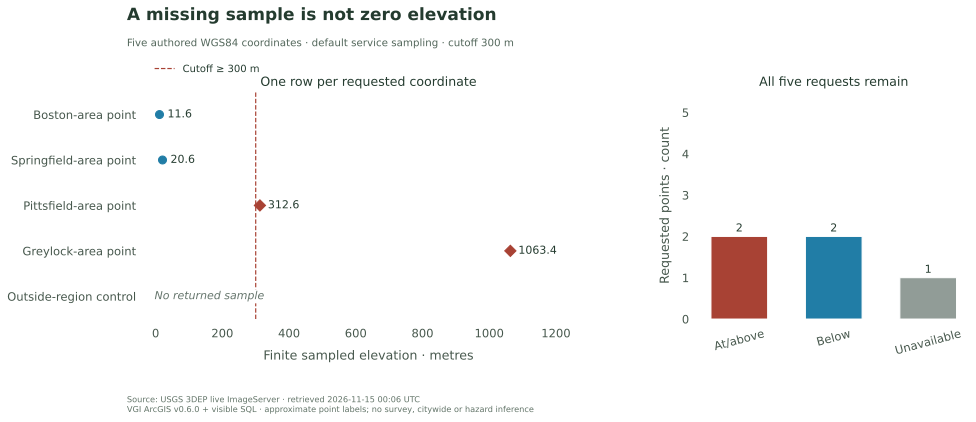

**2 of 4 finite sampled points meet the ≥300 m cutoff.** The request roster still contains all 5 points, with 1 unavailable. Omitting them would change the denominator; filling them with zero would invent elevations. Labels describe these individual coordinates, not all of each place.

In [13]:
display(inventory)
display(accounting)
example.sample_accounting(inventory, accounting, ELEVATION_THRESHOLD_M, started_utc)
finite = int(inventory.elevation_m.notna().sum())
selected = int((inventory.elevation_class == "At or above cutoff").sum())
prose(f"**{selected} of {finite} finite sampled points meet the ≥{ELEVATION_THRESHOLD_M:g} m cutoff.** The request roster still contains all {len(inventory)} points, with {len(inventory)-finite} unavailable. Omitting them would change the denominator; filling them with zero would invent elevations. Labels describe these individual coordinates, not all of each place.")

### Verify attribution and complete accounting

The checks deliberately do not require a fixed number of returned samples or a specific elevation: the live source can change. They require at least one finite sample, preserve all requested points, reject unattributed/duplicate service IDs, and keep unavailable values unclassified. Resolution is displayed as reported source-raster metadata; it is not used as an error bar.

In [14]:
%%sql checks <<
SELECT 'Five unique requested IDs' AS check_name,count(*)=5 AND count(DISTINCT point_index)=5 AS passed FROM requested_points
UNION ALL SELECT 'Returned IDs are attributable',count(*)>0 AND bool_and(point_index IS NOT NULL AND point_index BETWEEN 0 AND 4) FROM raw_samples
UNION ALL SELECT 'No duplicate returned IDs',count(*)=count(DISTINCT point_index) FROM raw_samples
UNION ALL SELECT 'Returned locations use WGS84',bool_and(coalesce((spatial_reference::JSON->>'wkid')::INTEGER=4326,false)) FROM raw_samples
UNION ALL SELECT 'Returned coordinates match requested',bool_and(coalesce(abs(s.sample_x-p.longitude)<1e-8 AND abs(s.sample_y-p.latitude)<1e-8,false)) FROM raw_samples s JOIN requested_points p USING(point_index)
UNION ALL SELECT 'Left join preserves all five inputs',count(*)=5 AND count(DISTINCT point_index)=5 FROM point_inventory
UNION ALL SELECT 'At least one finite elevation',count(*) FILTER(WHERE elevation_m IS NOT NULL)>0 FROM point_inventory
UNION ALL SELECT 'No invented value for omitted rows',count(*) FILTER(WHERE NOT returned AND elevation_m IS NOT NULL)=0 FROM point_inventory
UNION ALL SELECT 'Elevation classifications retain unknown',bool_and((elevation_m IS NULL)=(elevation_class='Unavailable')) FROM classified
UNION ALL SELECT 'Inclusive cutoff implemented',bool_and((elevation_class='At or above cutoff')=(elevation_m>={{ ELEVATION_THRESHOLD_M }})) FROM classified WHERE elevation_m IS NOT NULL
UNION ALL SELECT 'All requested rows have one class',count(*)=5 AND bool_and(elevation_class IN ('At or above cutoff','Below cutoff','Unavailable')) FROM classified
UNION ALL SELECT 'No raw service row is lost',sum(returned::INTEGER)=(SELECT count(*) FROM raw_samples) FROM point_inventory;

In [15]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all()
assert accounting.requested_points.sum() == 5 and len(accounting) == 3
prose(f"**All {len(checks)} SQL checks and three-category accounting passed.** Missing samples remain explicit, and no inference about sea level, safety or accuracy follows from availability.")

,check_name,passed
0,Five unique requested IDs,True
1,Returned IDs are attributable,True
2,No duplicate returned IDs,True
3,Returned locations use WGS84,True
4,Returned coordinates match requested,True
5,Left join preserves all five inputs,True
6,At least one finite elevation,True
7,No invented value for omitted rows,True
8,Elevation classifications retain unknown,True
9,Inclusive cutoff implemented,True


**All 12 SQL checks and three-category accounting passed.** Missing samples remain explicit, and no inference about sea level, safety or accuracy follows from availability.

### Change the classification after retrieval

Set **`ELEVATION_THRESHOLD_M = 1000`**, restart and run all into a separate experiment. With an identical returned-sample hash, numeric elevations, omitted IDs and raster provenance must stay fixed while only cutoff membership changes. If the hash differs, first inspect the live source difference; do not attribute every change to the threshold. Service failures stop execution; there is no fabricated or replay fallback.

In [16]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
for key, value in previous_env.items():
    if value is not None:
        os.environ[key] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-arcgis](https://github.com/Query-farm/vgi-arcgis)